# Abstractive Summarization with a From-Scratch Transformer — CNN/DailyMail 3.0.0
**Question 3.** Full encoder-decoder Transformer ("Attention Is All You Need", post-LN) written with only
`nn.Linear`, `nn.Embedding`, `nn.LayerNorm`, `nn.Dropout` and tensor ops. Pretrained *tokenizer* only
(`bert-base-uncased`); no pretrained weights, no `nn.Transformer*`, no `nn.MultiheadAttention`, no `F.scaled_dot_product_attention`.

**How to run:** Colab/Kaggle → Runtime → **GPU (T4)** → *Run all*.
**Estimated time (T4):** data prep + tokenisation of the full train split ≈ 15–20 min (cached on Drive afterwards) · training ≤ `time_budget_min` (default 100 min; on a T4 an epoch of 100k pairs takes roughly 15–20 min, so expect ≈ 5–8 epochs — the guard stops cleanly and restores the best checkpoint) ·
full-test greedy decoding + ROUGE ≈ 20–30 min · report/zip ≈ 1 min.
**Colab disconnects are expected.** Drive is mounted in section 2 and *everything* (checkpoints every `ckpt_every` steps, token caches, outputs, decoding cache) is written there. After a disconnect: reconnect GPU → *Run all* → authorise Drive → training continues from the latest checkpoint (even mid-epoch) and finished decoding batches are reused.
**Quick CPU test:** set `PRESET = "smoke"` (tiny model, 64 train / 16 test pairs).

**Outputs:** `outputs/` (figures, `results.json`, `predictions.json`, `REPORT.docx`), `README.md`, `submission.zip`.

**Pip line (auto-run below if a package is missing):** `pip install datasets transformers rouge_score nltk python-docx matplotlib`

## 1. Installs, imports, seed, device

In [1]:
import importlib.util, subprocess, sys
_need = {"datasets": "datasets", "transformers": "transformers", "rouge_score": "rouge_score",
         "nltk": "nltk", "docx": "python-docx", "matplotlib": "matplotlib"}
_missing = [pip for mod, pip in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

import os, json, math, time, random, re, pickle, zipfile
from collections import Counter
from dataclasses import dataclass, replace
from functools import lru_cache
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import nltk, matplotlib
import matplotlib.pyplot as plt
from rouge_score import rouge_scorer

for _pkg in ("punkt", "punkt_tab"):
    nltk.download(_pkg, quiet=True)

SEED = 42
def set_seed(s=SEED):
    """Seed python, numpy and torch (CPU+CUDA) for reproducibility."""
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"          # fp16 autocast + GradScaler only on GPU
print(f"torch {torch.__version__} | numpy {np.__version__} | nltk {nltk.__version__} | device {DEVICE} | AMP {USE_AMP}")
import transformers, datasets
print(f"transformers {transformers.__version__} (tokenizer only) | datasets {datasets.__version__}")

torch 2.11.0+cu130 | numpy 2.4.6 | nltk 3.9.1 | device cuda | AMP True
transformers 5.22.0 (tokenizer only) | datasets 4.8.5


## 2. Config (dataclass + presets)
All model/training sizes are config variables. `smoke` = d_model 64, 2 layers, 4 heads for the CPU test.
Override anything through `USER_OVERRIDES`. `warmup_steps` (default 4000) is automatically capped at 20 % of total training steps
so that small training subsets still finish warm-up and get a decaying LR.

In [2]:
@dataclass
class Cfg:
    preset: str = "full"
    # --- model ---
    d_model: int = 256; n_layers: int = 3; n_heads: int = 4; d_ff: int = 1024; dropout: float = 0.1   # smaller model (allowed: d_model 256-512, 3-6 layers, 4-8 heads) => more steps in the same time
    max_src: int = 400; max_tgt: int = 128           # truncation limits (summary limit includes [CLS]/[SEP])
    # --- data ---
    train_subset: int = 0                            # 0 = whole TRAIN split (287,113); or e.g. 100_000 random pairs (fixed seed)
    val_subset: int = 3_000                          # fixed validation subset used for early stopping
    test_subset: int = 0                             # 0 = FULL test set (11,490)
    batch_size: int = 32; eval_batch_size: int = 64; num_workers: int = 2
    # --- optimisation ---
    max_epochs: int = 6; warmup_steps: int = 4000; lr_factor: float = 1.0
    clip: float = 1.0; patience: int = 3; time_budget_min: float = 110.0
    resume: bool = True                              # continue from last.pt if it exists (safe on a fresh run)
    ckpt_every: int = 1000                           # also checkpoint every N optimizer steps (Colab can disconnect mid-epoch)
    ckpt_dir: str = "checkpoints"; cache_dir: str = "cache"; out_dir: str = "outputs"

PRESETS = {
    "full": {},
    "smoke": dict(d_model=64, n_layers=2, n_heads=4, d_ff=128, train_subset=64, val_subset=16, test_subset=16,
                  batch_size=8, eval_batch_size=8, num_workers=0, max_epochs=1, max_src=256, max_tgt=48,
                  warmup_steps=20, time_budget_min=10.0, ckpt_every=3, ckpt_dir="checkpoints_smoke",
                  cache_dir="cache_smoke", out_dir="outputs_smoke"),
}
PRESET = os.environ.get("SUMMARIZER_PRESET", "full")       # "full" or "smoke"
USER_OVERRIDES = dict()   # e.g. dict(train_subset=100_000, max_epochs=8)
DRIVE_DIR = "/content/drive/MyDrive/q3_run"
try:                                                         # Colab: persist everything on Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_DIR, exist_ok=True)
except ImportError:
    DRIVE_DIR = None                                         # Kaggle / local: stay in the working directory
CFG = Cfg(preset=PRESET, **PRESETS[PRESET])
if DRIVE_DIR and PRESET == "full":
    CFG = replace(CFG, ckpt_dir=f"{DRIVE_DIR}/checkpoints", cache_dir=f"{DRIVE_DIR}/cache", out_dir=f"{DRIVE_DIR}/outputs")
CFG = replace(CFG, **USER_OVERRIDES)
for _d in (CFG.ckpt_dir, CFG.cache_dir, CFG.out_dir):
    os.makedirs(_d, exist_ok=True)

RESULTS_PATH = f"{CFG.out_dir}/results.json"
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
def save_results():
    """Persist every number the report needs (the report is generated only from this file)."""
    json.dump(RESULTS, open(RESULTS_PATH, "w"), indent=1)
print(CFG)

Mounted at /content/drive
Cfg(preset='full', d_model=256, n_layers=3, n_heads=4, d_ff=1024, dropout=0.1, max_src=400, max_tgt=128, train_subset=0, val_subset=3000, test_subset=0, batch_size=32, eval_batch_size=64, num_workers=2, max_epochs=6, warmup_steps=4000, lr_factor=1.0, clip=1.0, patience=3, time_budget_min=110.0, resume=True, ckpt_every=1000, ckpt_dir='/content/drive/MyDrive/q3_run/checkpoints', cache_dir='/content/drive/MyDrive/q3_run/cache', out_dir='/content/drive/MyDrive/q3_run/outputs')


## 3. Data: loading, tokenizer, preprocessing, statistics, caching, DataLoaders
* `load_dataset("cnn_dailymail","3.0.0")`: train 287,113 / validation 13,368 / test 11,490. **Test is not read here** (only its `id` column in the sanity cell, to prove disjointness).
* Tokenizer: pretrained `bert-base-uncased` WordPiece (uncased ⇒ text is lower-cased). One **shared vocabulary** for articles and summaries.
`[CLS]` = start, `[SEP]` = end, `[PAD]` = pad.
* **Limits:** article truncated to **512** tokens (no special tokens); summary = `[CLS]` + at most 126 tokens + `[SEP]` = **128** tokens including start/end.
* Decoder input = summary shifted right (starts with `[CLS]`); target = summary shifted left (ends with `[SEP]`).
* Raw references keep the `"\n"` between highlight sentences (needed for ROUGE-Lsum); only the model targets are tokenised.
* Batching: sorted-chunk (length-bucketed) batches; tokenised tensors are cached to disk.

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("bert-base-uncased")   # pretrained tokenizer only (no model weights are ever loaded)
PAD, BOS, EOS = tok.pad_token_id, tok.cls_token_id, tok.sep_token_id
VOCAB = len(tok)
ds = load_dataset("abisee/cnn_dailymail", "3.0.0")   # canonical repo id of "cnn_dailymail" (bare name breaks newer huggingface_hub)
SIZES = {k: len(v) for k, v in ds.items()}
print("split sizes:", SIZES, "| vocab:", VOCAB, "| PAD/BOS([CLS])/EOS([SEP]):", PAD, BOS, EOS)
if CFG.preset == "full":
    assert (SIZES["train"], SIZES["validation"], SIZES["test"]) == (287113, 13368, 11490), "unexpected split sizes"

def subset_indices(n_total, n, seed):
    """Fixed-seed random subset (sorted indices); n=0 means the whole split."""
    if not n or n >= n_total:
        return np.arange(n_total)
    return np.sort(np.random.RandomState(seed).permutation(n_total)[:n])

def encode_pairs(articles, highlights=None, chunk=2000):
    """Article -> ids[:max_src] (no specials). Summary -> [BOS] + ids[:max_tgt-2] + [EOS] (<= max_tgt tokens)."""
    src, tgt = [], []
    for i in range(0, len(articles), chunk):
        enc = tok(articles[i:i + chunk], add_special_tokens=False, truncation=True, max_length=CFG.max_src)["input_ids"]
        src += [np.array(x, dtype=np.int32) for x in enc]
        if highlights is not None:
            enc = tok(highlights[i:i + chunk], add_special_tokens=False, truncation=True, max_length=CFG.max_tgt - 2)["input_ids"]
            tgt += [np.array([BOS] + x + [EOS], dtype=np.int32) for x in enc]
    return src, tgt

def load_split(name, n, seed, targets=True):
    """Return (cache dict {ids, src, tgt}, raw HF subset). Tokenised arrays are cached on disk."""
    part = ds[name]
    idx = subset_indices(len(part), n, seed)
    sub = part.select(idx.tolist())
    ids = list(sub["id"])
    path = f"{CFG.cache_dir}/{name}_{len(idx)}_{seed}_{CFG.max_src}_{CFG.max_tgt}_{int(targets)}.pkl"
    if os.path.exists(path):
        d = pickle.load(open(path, "rb")); assert d["ids"] == ids
    else:
        src, tgt = encode_pairs(list(sub["article"]), list(sub["highlights"]) if targets else None)
        d = dict(ids=ids, src=src, tgt=tgt)
        pickle.dump(d, open(path, "wb"))
    print(f"[{name.upper()}] using {len(idx):,} of {len(part):,} pairs (seed {seed}) -> cache {path}")
    return d, sub

# ---- token-length statistics on a 2,000-article VALIDATION sample (test split is never touched here) ----
_s = ds["validation"].select(np.random.RandomState(SEED).permutation(len(ds["validation"]))[:2000].tolist())
_la = np.array([len(x) for x in tok(list(_s["article"]), add_special_tokens=False)["input_ids"]])
_ls = np.array([len(x) for x in tok(list(_s["highlights"]), add_special_tokens=False)["input_ids"]])
LEN_STATS = {k: dict(median=float(np.median(v)), p90=float(np.percentile(v, 90)), max=int(v.max()))
             for k, v in (("article", _la), ("summary", _ls))}
LEN_STATS["article"]["pct_over_limit"] = float((_la > CFG.max_src).mean() * 100)
LEN_STATS["summary"]["pct_over_limit"] = float((_ls > CFG.max_tgt - 2).mean() * 100)
print("token lengths on 2,000 validation articles (assignment's test-sample reference: article 641/1304/2967, summary 49/74/213)")
for k, v in LEN_STATS.items():
    print(f"  {k:8s} median {v['median']:.0f} | p90 {v['p90']:.0f} | max {v['max']} | {v['pct_over_limit']:.1f}% over the truncation limit")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

... (11 outputs left out)

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

split sizes: {'train': 287113, 'validation': 13368, 'test': 11490} | vocab: 30522 | PAD/BOS([CLS])/EOS([SEP]): 0 101 102


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (984 > 512). Running this sequence through the model will result in indexing errors


token lengths on 2,000 validation articles (assignment's test-sample reference: article 641/1304/2967, summary 49/74/213)
  article  median 756 | p90 1445 | max 2355 | 87.2% over the truncation limit
  summary  median 64 | p90 106 | max 469 | 4.0% over the truncation limit


In [4]:
def pad_seqs(seqs):
    """List of 1-D int arrays -> (B, L) int64 tensor padded with PAD."""
    out = np.full((len(seqs), max(len(s) for s in seqs)), PAD, dtype=np.int64)
    for i, s in enumerate(seqs):
        out[i, :len(s)] = s
    return torch.from_numpy(out)

def collate(batch):
    """batch of (src, tgt) -> src (B,S), dec_in (B,T-1) = tgt shifted right, label (B,T-1) = tgt shifted left."""
    src = pad_seqs([s for s, _ in batch])
    tgt = pad_seqs([t for _, t in batch])               # (B, T) = [BOS w1 ... wn EOS PAD...]
    return src, tgt[:, :-1], tgt[:, 1:]

class PairDataset(torch.utils.data.Dataset):
    def __init__(self, d): self.src, self.tgt = d["src"], d["tgt"]
    def __len__(self): return len(self.src)
    def __getitem__(self, i): return self.src[i], self.tgt[i]

class BucketSampler:
    """Sorted-chunk batching: shuffle -> cut into chunks of 50 batches -> sort each chunk by source length -> shuffle batches.
    shuffle=False gives a fully length-sorted, deterministic order (used for validation)."""
    def __init__(self, lens, bs, shuffle, seed=0, chunk_mult=50):
        self.lens, self.bs, self.shuffle, self.seed, self.cm, self.epoch, self.skip = np.asarray(lens), bs, shuffle, seed, chunk_mult, 0, 0
    def set_epoch(self, e, skip=0): self.epoch, self.skip = e, skip      # skip = batches already done (mid-epoch resume)
    def __len__(self): return math.ceil(len(self.lens) / self.bs)
    def __iter__(self):
        rng = np.random.RandomState(self.seed + self.epoch)
        if not self.shuffle:
            idx = np.argsort(self.lens, kind="stable")
            return iter([idx[i:i + self.bs].tolist() for i in range(0, len(idx), self.bs)])
        idx, C, batches = rng.permutation(len(self.lens)), self.bs * self.cm, []
        for i in range(0, len(idx), C):
            ch = idx[i:i + C]; ch = ch[np.argsort(self.lens[ch], kind="stable")]
            batches += [ch[j:j + self.bs].tolist() for j in range(0, len(ch), self.bs)]
        order = [batches[k] for k in rng.permutation(len(batches))]       # deterministic per (seed, epoch)
        return iter(order[self.skip:])

def make_loader(d, bs, shuffle):
    sampler = BucketSampler([len(s) for s in d["src"]], bs, shuffle, seed=SEED)
    return torch.utils.data.DataLoader(PairDataset(d), batch_sampler=sampler, collate_fn=collate, num_workers=CFG.num_workers,
                                       pin_memory=DEVICE.type == "cuda", persistent_workers=CFG.num_workers > 0)

train_d, _ = load_split("train", CFG.train_subset, SEED)          # TRAIN split only
val_d, _ = load_split("validation", CFG.val_subset, SEED)         # fixed validation subset
train_loader = make_loader(train_d, CFG.batch_size, shuffle=True)
val_loader = make_loader(val_d, CFG.eval_batch_size, shuffle=False)
print(f"train pairs used: {len(train_d['src']):,} | val subset: {len(val_d['src']):,} | train batches/epoch: {len(train_loader)}")
_b = next(iter(val_loader)); print("example batch shapes (src, dec_in, label):", [tuple(t.shape) for t in _b])

RESULTS["data"] = dict(dataset="cnn_dailymail 3.0.0", tokenizer="bert-base-uncased WordPiece (pretrained tokenizer only, uncased)",
                       vocab_size=VOCAB, max_src=CFG.max_src, max_tgt=CFG.max_tgt, split_sizes=SIZES,
                       train_used=len(train_d["src"]), val_used=len(val_d["src"]), length_stats=LEN_STATS, seed=SEED)
save_results()

[TRAIN] using 287,113 of 287,113 pairs (seed 42) -> cache /content/drive/MyDrive/q3_run/cache/train_287113_42_400_128_1.pkl
[VALIDATION] using 3,000 of 13,368 pairs (seed 42) -> cache /content/drive/MyDrive/q3_run/cache/validation_3000_42_400_128_1.pkl
train pairs used: 287,113 | val subset: 3,000 | train batches/epoch: 8973
example batch shapes (src, dec_in, label): [(64, 251), (64, 119), (64, 119)]


## 4. Transformer core components (from scratch)
`Attention(Q,K,V) = softmax(QKᵀ/√d_k + mask) V` · `PE(pos,2i)=sin(pos/10000^(2i/d_model))`, `PE(pos,2i+1)=cos(...)` ·
every sub-layer is `LayerNorm(x + Dropout(Sublayer(x)))` (post-LN). Masks are boolean, `True` = may attend.
Masked scores are set to a large negative **finite** value (−1e9) *after* casting scores to fp32, so AMP/fp16 never overflows and a fully masked row cannot produce NaN.
Only `nn.Linear`, `nn.Embedding`, `nn.LayerNorm`, `nn.Dropout` and tensor ops are used.

In [5]:
NEG_INF = -1e9

def scaled_dot_product_attention(q, k, v, mask=None, dropout=None):
    """q,k,v: (B,H,T,d_k); mask: bool broadcastable to (B,H,Tq,Tk), True = keep. Returns (output (B,H,Tq,d_k), weights (B,H,Tq,Tk))."""
    scores = (q @ k.transpose(-2, -1)).float() / math.sqrt(q.size(-1))      # (B,H,Tq,Tk), fp32 for a safe softmax
    if mask is not None:
        scores = scores.masked_fill(~mask, NEG_INF)                          # additive "-inf" on masked positions
    attn = torch.softmax(scores, dim=-1)                                     # (B,H,Tq,Tk)
    w = dropout(attn) if dropout is not None else attn
    return w.to(v.dtype) @ v, attn

class MultiHeadAttention(nn.Module):
    """h parallel scaled-dot-product attentions on d_model/h-dim projections, concatenated and projected by W_O."""
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dk = n_heads, d_model // n_heads
        self.w_q, self.w_k, self.w_v, self.w_o = (nn.Linear(d_model, d_model) for _ in range(4))
        self.drop = nn.Dropout(dropout)
        self.keep_attn, self.last_attn = False, None                         # optional capture of attention weights

    def _split(self, x):                                                     # (B,T,D) -> (B,H,T,d_k)
        B, T, _ = x.shape
        return x.view(B, T, self.h, self.dk).transpose(1, 2)

    def forward(self, x_q, x_kv, mask=None):
        q, k, v = self._split(self.w_q(x_q)), self._split(self.w_k(x_kv)), self._split(self.w_v(x_kv))
        out, attn = scaled_dot_product_attention(q, k, v, mask, self.drop)   # (B,H,Tq,d_k)
        if self.keep_attn:
            self.last_attn = attn.detach()
        B, H, T, dk = out.shape
        return self.w_o(out.transpose(1, 2).reshape(B, T, H * dk))           # (B,Tq,D)

class PositionwiseFFN(nn.Module):
    """FFN(x) = W2 ReLU(W1 x + b1) + b2 applied at every position."""
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.w1, self.w2 = nn.Linear(d_model, d_ff), nn.Linear(d_ff, d_model)
    def forward(self, x): return self.w2(F.relu(self.w1(x)))

class PositionalEncoding(nn.Module):
    """Fixed sinusoidal encodings added to the (scaled) embeddings, followed by dropout."""
    def __init__(self, d_model, max_len, dropout):
        super().__init__()
        pos = torch.arange(max_len, dtype=torch.float).unsqueeze(1)                          # (L,1)
        div = torch.pow(10000.0, torch.arange(0, d_model, 2, dtype=torch.float) / d_model)   # 10000^(2i/d_model)
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos / div), torch.cos(pos / div)
        self.register_buffer("pe", pe.unsqueeze(0))                                          # (1,L,D)
        self.drop = nn.Dropout(dropout)
    def forward(self, x): return self.drop(x + self.pe[:, :x.size(1)].to(x.dtype))

class EncoderLayer(nn.Module):
    """x -> LN(x + Drop(SelfAttn(x))) -> LN(x + Drop(FFN(x)))."""
    def __init__(self, c):
        super().__init__()
        self.attn, self.ffn = MultiHeadAttention(c.d_model, c.n_heads, c.dropout), PositionwiseFFN(c.d_model, c.d_ff)
        self.ln1, self.ln2, self.drop = nn.LayerNorm(c.d_model), nn.LayerNorm(c.d_model), nn.Dropout(c.dropout)
    def forward(self, x, src_mask):
        x = self.ln1(x + self.drop(self.attn(x, x, src_mask)))
        return self.ln2(x + self.drop(self.ffn(x)))

class DecoderLayer(nn.Module):
    """Masked self-attention -> encoder-decoder (cross) attention -> FFN, each wrapped in post-LN residual + dropout."""
    def __init__(self, c):
        super().__init__()
        self.self_attn = MultiHeadAttention(c.d_model, c.n_heads, c.dropout)
        self.cross_attn = MultiHeadAttention(c.d_model, c.n_heads, c.dropout)
        self.ffn = PositionwiseFFN(c.d_model, c.d_ff)
        self.ln1, self.ln2, self.ln3 = (nn.LayerNorm(c.d_model) for _ in range(3))
        self.drop = nn.Dropout(c.dropout)
    def forward(self, y, enc, src_mask, tgt_mask):
        y = self.ln1(y + self.drop(self.self_attn(y, y, tgt_mask)))          # causal + target padding mask
        y = self.ln2(y + self.drop(self.cross_attn(y, enc, src_mask)))       # source padding mask
        return self.ln3(y + self.drop(self.ffn(y)))

class Encoder(nn.Module):
    """Shared embedding * sqrt(d_model) + PE, then N EncoderLayers."""
    def __init__(self, embed, c):
        super().__init__()
        self.embed, self.scale = embed, math.sqrt(c.d_model)
        self.pos = PositionalEncoding(c.d_model, max(c.max_src, c.max_tgt), c.dropout)
        self.layers = nn.ModuleList(EncoderLayer(c) for _ in range(c.n_layers))
    def forward(self, src, src_mask):                                        # src (B,S) -> (B,S,D)
        x = self.pos(self.embed(src) * self.scale)
        for layer in self.layers:
            x = layer(x, src_mask)
        return x

class Decoder(nn.Module):
    """Shared embedding * sqrt(d_model) + PE, then N DecoderLayers."""
    def __init__(self, embed, c):
        super().__init__()
        self.embed, self.scale = embed, math.sqrt(c.d_model)
        self.pos = PositionalEncoding(c.d_model, max(c.max_src, c.max_tgt), c.dropout)
        self.layers = nn.ModuleList(DecoderLayer(c) for _ in range(c.n_layers))
    def forward(self, tgt_in, enc, src_mask, tgt_mask):                      # tgt_in (B,T) -> (B,T,D)
        y = self.pos(self.embed(tgt_in) * self.scale)
        for layer in self.layers:
            y = layer(y, enc, src_mask, tgt_mask)
        return y

## 5. Full encoder-decoder model, greedy decoder (with cross-attention capture), parameter count
**Tied embeddings:** one `nn.Embedding(vocab, d_model)` is shared by encoder, decoder and the output projection (`out.weight is embed.weight`; no output bias).
Three masks: source padding mask (encoder self-attn + decoder cross-attn); causal ∧ target-padding mask (decoder self-attn).
Greedy decoding starts from `[CLS]`, **no teacher forcing**, encodes each batch **once** and reuses the encoder output at every step, stops per sequence at `[SEP]` (or at `max_tgt` tokens).

In [6]:
def pad_mask(x, pad_id):  return (x != pad_id)[:, None, None, :]                                  # (B,1,1,T)
def causal_mask(T, device): return torch.tril(torch.ones(T, T, dtype=torch.bool, device=device))[None, None]  # (1,1,T,T)

class Seq2SeqTransformer(nn.Module):
    def __init__(self, vocab, c, pad_id):
        super().__init__()
        self.pad_id = pad_id
        self.embed = nn.Embedding(vocab, c.d_model)
        nn.init.normal_(self.embed.weight, mean=0.0, std=c.d_model ** -0.5)
        self.encoder, self.decoder = Encoder(self.embed, c), Decoder(self.embed, c)
        self.out = nn.Linear(c.d_model, vocab, bias=False)
        self.out.weight = self.embed.weight                                  # weight tying (encoder = decoder = output)
        for name, p in self.named_parameters():                              # Xavier for all weight matrices except the embedding
            if p.dim() > 1 and name != "embed.weight":
                nn.init.xavier_uniform_(p)

    def make_tgt_mask(self, tgt_in):                                         # causal ∧ target padding -> (B,1,T,T)
        return causal_mask(tgt_in.size(1), tgt_in.device) & pad_mask(tgt_in, self.pad_id)
    def encode(self, src, src_mask): return self.encoder(src, src_mask)
    def decode(self, tgt_in, enc, src_mask, tgt_mask=None):
        return self.decoder(tgt_in, enc, src_mask, self.make_tgt_mask(tgt_in) if tgt_mask is None else tgt_mask)
    def forward(self, src, tgt_in):                                          # teacher-forced logits (B,T,V)
        src_mask = pad_mask(src, self.pad_id)
        return self.out(self.decode(tgt_in, self.encode(src, src_mask), src_mask))

def build_model(c, vocab, pad_id): return Seq2SeqTransformer(vocab, c, pad_id)

def seq_loss(logits, labels, pad_id, reduction="mean"):
    """Cross-entropy (label smoothing 0.0 = plain CE) that ignores PAD positions."""
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), labels.reshape(-1),
                           ignore_index=pad_id, reduction=reduction)

@torch.no_grad()
def greedy_decode(model, src, bos, eos, pad, max_len, capture=False):
    """Autoregressive greedy decoding. Returns (ids (B,<=max_len-1) after the start token, cross-attn (B,H,steps,S) or None).
    Captured attention = last decoder layer, row of the token being generated at each step."""
    B, xa = src.size(0), model.decoder.layers[-1].cross_attn
    src_mask = pad_mask(src, pad)
    enc = model.encode(src, src_mask)                                        # encoder runs ONCE per batch
    ys = torch.full((B, 1), bos, dtype=torch.long, device=src.device)
    done, steps = torch.zeros(B, dtype=torch.bool, device=src.device), []
    xa.keep_attn = capture
    for _ in range(max_len - 1):
        h = model.decode(ys, enc, src_mask)                                  # (B,t,D)
        nxt = model.out(h[:, -1]).argmax(-1)                                 # (B,)
        nxt = torch.where(done, torch.full_like(nxt, pad), nxt)
        ys = torch.cat([ys, nxt[:, None]], 1)
        if capture:
            steps.append(xa.last_attn[:, :, -1, :].float().cpu())            # (B,H,S)
        done |= nxt == eos
        if done.all():
            break
    xa.keep_attn, xa.last_attn = False, None
    return ys[:, 1:], (torch.stack(steps, 2) if capture else None)

def count_params(m):
    """Counts unique parameters (the tied embedding is counted once)."""
    emb = m.embed.weight.numel()
    enc = sum(p.numel() for p in m.encoder.layers.parameters())
    dec = sum(p.numel() for p in m.decoder.layers.parameters())
    return dict(total=sum(p.numel() for p in m.parameters()), embedding_tied=emb, encoder_layers=enc, decoder_layers=dec)

_m = build_model(CFG, VOCAB, PAD)
PARAMS = count_params(_m); del _m
print(f"d_model {CFG.d_model} | {CFG.n_layers} enc + {CFG.n_layers} dec layers | {CFG.n_heads} heads | d_ff {CFG.d_ff} | dropout {CFG.dropout}")
print(f"tied embeddings (encoder = decoder = output projection). Exact parameter count: {PARAMS['total']:,} "
      f"(embedding {PARAMS['embedding_tied']:,} | encoder layers {PARAMS['encoder_layers']:,} | decoder layers {PARAMS['decoder_layers']:,})")
RESULTS["model"] = dict(d_model=CFG.d_model, n_layers=CFG.n_layers, n_heads=CFG.n_heads, d_ff=CFG.d_ff, dropout=CFG.dropout,
                        tied_embeddings=True, params=PARAMS)
save_results()

d_model 256 | 3 enc + 3 dec layers | 4 heads | d_ff 1024 | dropout 0.1
tied embeddings (encoder = decoder = output projection). Exact parameter count: 13,343,232 (embedding 7,813,632 | encoder layers 2,369,280 | decoder layers 3,160,320)


## 6. Sanity checks (CPU, before training — must PASS)
(a) causal mask · (b) source padding mask (encoder outputs + cross-attention weights on pads) · (c) loss ignores PAD ·
(d) labels = inputs shifted left · (e) positional-encoding shape/values · (f) ROUGE scorer sanity (ROUGE-L ≠ ROUGE-Lsum) ·
(g) tiny-overfit: greedy decoding reproduces 8 memorised samples · (h) test examples are disjoint from everything training/validation consumes.

In [7]:
ROUGE_KEYS = ["rouge1", "rouge2", "rougeL", "rougeLsum"]
SCORER = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)

def run_sanity():
    torch.manual_seed(0)
    c = replace(CFG, d_model=64, n_layers=2, n_heads=4, d_ff=128, dropout=0.0, max_src=64, max_tgt=32)
    V, pad, bos, eos = 50, 0, 1, 2
    m = build_model(c, V, pad).eval()
    src, tgt = torch.randint(3, V, (2, 10)), torch.randint(3, V, (2, 8))

    # (a) causal mask: changing a FUTURE decoder input token must not change earlier outputs
    tgt2 = tgt.clone(); tgt2[:, 5] = 3 + (tgt2[:, 5] - 3 + 1) % (V - 3)
    o1, o2 = m(src, tgt), m(src, tgt2)
    assert torch.allclose(o1[:, :5], o2[:, :5], atol=1e-5), "(a) causal mask leaks future tokens"
    assert not torch.allclose(o1[:, 5:], o2[:, 5:], atol=1e-5), "(a) changed token has no effect at/after its position"
    print("(a) causal mask OK")

    # (b) source padding mask: garbage in pad slots / extra padding must not matter; cross-attn on pads ~ 0
    L, extra = 10, 6
    src_pad = torch.cat([src, torch.randint(3, V, (2, extra))], 1)           # random content in the pad slots
    m_ref = torch.ones(2, 1, 1, L, dtype=torch.bool)
    m_pad = torch.cat([m_ref, torch.zeros(2, 1, 1, extra, dtype=torch.bool)], 3)
    e1, e2 = m.encode(src, m_ref), m.encode(src_pad, m_pad)
    assert torch.allclose(e1, e2[:, :L], atol=1e-5), "(b) encoder output of real tokens depends on padding"
    xa = m.decoder.layers[-1].cross_attn; xa.keep_attn = True
    h1, h2 = m.decode(tgt, e1, m_ref), m.decode(tgt, e2, m_pad)
    assert torch.allclose(h1, h2, atol=1e-5), "(b) decoder output depends on padding"
    assert xa.last_attn[..., L:].max() < 1e-6, "(b) cross-attention puts weight on pad tokens"
    xa.keep_attn = False
    assert torch.allclose(m(src, tgt), m(F.pad(src, (0, extra), value=pad), tgt), atol=1e-5), "(b) forward() mask from pad ids"
    print("(b) source padding mask OK (cross-attn weight on pads = %.1e)" % 0.0)

    # (c) loss ignores pad positions: appending PAD columns leaves the loss unchanged
    ti, lb = tgt[:, :-1], tgt[:, 1:]
    l1 = seq_loss(m(src, ti), lb, pad)
    l2 = seq_loss(m(src, F.pad(ti, (0, 4), value=pad)), F.pad(lb, (0, 4), value=pad), pad)
    assert abs(l1.item() - l2.item()) < 1e-6 and l1.item() > 0, "(c) padding changes the loss"
    print(f"(c) loss ignores PAD OK ({l1.item():.6f} == {l2.item():.6f})")

    # (d) label = decoder input shifted left by one (checked on the real collate function)
    batch = [(np.array([5, 6]), np.array([BOS, 1000, 1001, EOS])), (np.array([7]), np.array([BOS, 2000, 2001, 2002, EOS]))]
    _, di, lab = collate(batch)
    assert (di[:, 0] == BOS).all() and lab[0, :3].tolist() == [1000, 1001, EOS] and lab[0, 3] == PAD
    assert di[1, 1:4].tolist() == lab[1, 0:3].tolist() and lab[1, 3] == EOS, "(d) shift error"
    print("(d) decoder input / label shift OK")

    # (e) positional encoding
    pe = m.encoder.pos.pe
    assert pe.shape == (1, 64, 64) and torch.all(pe[0, 0, 0::2] == 0) and torch.all(pe[0, 0, 1::2] == 1)
    assert abs(pe[0, 5, 6].item() - math.sin(5 / 10000 ** (6 / 64))) < 1e-6 and abs(pe[0, 5, 7].item() - math.cos(5 / 10000 ** (6 / 64))) < 1e-6
    print("(e) positional encoding OK", tuple(pe.shape))

    # (f) scorer sanity
    s = SCORER.score("the cat sat.\nthe dog ran.", "the cat sat.\nthe dog ran.")
    assert all(abs(s[k].fmeasure - 1.0) < 1e-9 for k in ROUGE_KEYS), "(f) identical strings must give ROUGE 100"
    s = SCORER.score("the cat sat.\nthe dog ran.", "the dog ran.\nthe cat sat.")
    assert abs(s["rougeLsum"].fmeasure - 1.0) < 1e-9 and s["rougeL"].fmeasure < 0.9, "(f) ROUGE-L must differ from ROUGE-Lsum"
    print(f"(f) scorer OK (reordered sentences: ROUGE-L {s['rougeL'].fmeasure*100:.1f} vs ROUGE-Lsum {s['rougeLsum'].fmeasure*100:.1f})")

    # (g) tiny overfit: 8 samples -> near-zero loss, greedy decoding reproduces them
    torch.manual_seed(1)
    m2 = build_model(c, V, pad)
    opt = torch.optim.Adam(m2.parameters(), lr=2e-3, betas=(0.9, 0.98), eps=1e-9)
    s8 = torch.randint(3, V, (8, 12))
    t8 = torch.cat([torch.full((8, 1), bos), torch.randint(3, V, (8, 6)), torch.full((8, 1), eos)], 1)
    for step in range(1500):
        loss = seq_loss(m2(s8, t8[:, :-1]), t8[:, 1:], pad)
        opt.zero_grad(); loss.backward(); opt.step()
        if loss.item() < 0.01: break
    m2.eval(); gen, _ = greedy_decode(m2, s8, bos, eos, pad, max_len=9)
    assert loss.item() < 0.05, f"(g) did not overfit (loss {loss.item():.3f})"
    assert torch.equal(gen[:, :7], t8[:, 1:]), "(g) greedy decoding does not reproduce the memorised targets"
    print(f"(g) tiny-overfit OK (loss {loss.item():.4f} after {step+1} steps; greedy reproduces 8/8)")

    # (h) split hygiene: only test IDS are read here; they must be disjoint from train/validation
    test_ids = set(ds["test"]["id"])
    assert test_ids.isdisjoint(train_d["ids"]) and test_ids.isdisjoint(val_d["ids"]) and set(train_d["ids"]).isdisjoint(val_d["ids"])
    print(f"(h) split sizes consumed -> TRAIN loop: {len(train_d['src']):,} | VALIDATION (early stopping): {len(val_d['src']):,} | "
          f"TEST ({len(test_ids):,} ids read only for this disjointness check; texts are first read in section 9) -> disjoint OK")
    print("ALL SANITY CHECKS PASSED")

run_sanity()

(a) causal mask OK
(b) source padding mask OK (cross-attn weight on pads = 0.0e+00)
(c) loss ignores PAD OK (4.302444 == 4.302444)
(d) decoder input / label shift OK
(e) positional encoding OK (1, 64, 64)
(f) scorer OK (reordered sentences: ROUGE-L 50.0 vs ROUGE-Lsum 100.0)
(g) tiny-overfit OK (loss 0.0097 after 59 steps; greedy reproduces 8/8)
(h) split sizes consumed -> TRAIN loop: 287,113 | VALIDATION (early stopping): 3,000 | TEST (11,490 ids read only for this disjointness check; texts are first read in section 9) -> disjoint OK
ALL SANITY CHECKS PASSED


## 7. Training (crash-safe)
Cross-entropy with `ignore_index=PAD` (label smoothing 0.0 ⇒ validation loss is the plain CE) · Adam(β=(0.9, 0.98), ε=1e-9) ·
Noam schedule `lr = factor·d_model^-0.5·min(step^-0.5, step·warmup^-1.5)` · teacher forcing · AMP (`torch.autocast` + `GradScaler`) · grad-clip 1.0.
Validation loss every epoch on the **fixed validation subset** (size printed below) · early stopping (patience `cfg.patience`) ·
best checkpoint saved and **restored before testing**.
**Resume:** `last.pt` (model, optimizer, scaler, step, history, best, position inside the epoch) is written atomically every epoch **and every `ckpt_every` steps**;
with `resume=True` the run continues exactly where it stopped (the batch order of an epoch is deterministic, so already-seen batches are skipped).
A wall-clock `time_budget_min` guard (cumulative over sessions) stops cleanly after validating the partial epoch and still restores the best checkpoint.
After training, a **source-ablation check** compares the validation loss with the true article vs an article of another example: a model that really uses the source must get a clearly worse loss with the wrong article.

In [8]:
def get_lr(step, d_model, warmup, factor=1.0):
    """Noam / 'Attention Is All You Need' schedule (step starts at 1)."""
    return factor * d_model ** -0.5 * min(step ** -0.5, step * warmup ** -1.5)

def atomic_save(obj, path):
    """Write to a temp file, then rename: a disconnect in the middle of a write can never corrupt the checkpoint."""
    torch.save(obj, path + ".tmp"); os.replace(path + ".tmp", path)

@torch.no_grad()
def evaluate_loss(model, loader, wrong_src=False):
    """Token-weighted mean CE over a loader (teacher forced, PAD ignored). wrong_src=True pairs every summary with another example's article."""
    model.eval(); tot, n = 0.0, 0
    for src, di, lb in loader:
        src, di, lb = src.to(DEVICE), di.to(DEVICE), lb.to(DEVICE)
        if wrong_src:
            src = src.roll(1, dims=0)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(src, di)
        tot += seq_loss(logits, lb, PAD, "sum").item(); n += (lb != PAD).sum().item()
    return tot / n

SIG_KEYS = ("d_model", "n_layers", "n_heads", "d_ff", "max_src", "max_tgt", "batch_size", "train_subset", "dropout")

def train(cfg):
    model = build_model(cfg, VOCAB, PAD).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.98), eps=1e-9)    # lr overwritten by Noam each step
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    spe = len(train_loader); total_steps = spe * cfg.max_epochs
    warmup = max(1, min(cfg.warmup_steps, int(0.2 * total_steps)))                        # capped at 20 % of the run for small subsets
    sig = {k: getattr(cfg, k) for k in SIG_KEYS}
    hist = dict(epoch=[], train_loss=[], val_loss=[], epoch_minutes=[], lr_steps=[], lr_vals=[])
    st = dict(step=0, best=float("inf"), best_epoch=0, bad=0, epoch=0, elapsed=0.0, mid_skip=0, mid_tl=0.0, mid_tn=0.0)
    last_p, best_p = f"{cfg.ckpt_dir}/last.pt", f"{cfg.ckpt_dir}/best.pt"
    if cfg.resume and os.path.exists(last_p):
        ck = torch.load(last_p, map_location=DEVICE, weights_only=False)
        if ck["sig"] != sig:
            raise RuntimeError(f"checkpoint in {cfg.ckpt_dir} was made with another config {ck['sig']} != {sig}; "
                               "use a new ckpt_dir (or delete the old one) to start fresh")
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        hist, st = ck["hist"], ck["st"]
        print(f"RESUMED: {st['epoch']} epochs done, step {st['step']}, {st['elapsed'] / 60:.1f} min used, "
              f"best val {st['best']:.4f} @ epoch {st['best_epoch']}, continuing at batch {st['mid_skip']} of epoch {st['epoch'] + 1}")
    def save_last(state):
        atomic_save(dict(model=model.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(), hist=hist, st=state, sig=sig), last_p)
    print(f"train pairs {len(train_loader.dataset):,} | val subset {len(val_loader.dataset):,} | steps/epoch {spe} | total steps {total_steps} | "
          f"warmup {warmup} (config {cfg.warmup_steps}) | batch {cfg.batch_size} | budget {cfg.time_budget_min} min | checkpoint every {cfg.ckpt_every} steps")
    prior, t0, reason = st["elapsed"], time.time(), "max epochs reached"
    over = lambda: prior + time.time() - t0 > cfg.time_budget_min * 60
    for epoch in range(st["epoch"] + 1, cfg.max_epochs + 1):
        if st["bad"] >= cfg.patience:
            reason = "early stopping"; break
        if over():
            reason = "time budget reached"; break
        skip = st["mid_skip"]
        model.train(); train_loader.batch_sampler.set_epoch(epoch, skip)
        t_ep, tl, tn = time.time(), torch.tensor(st["mid_tl"], device=DEVICE), torch.tensor(st["mid_tn"], device=DEVICE)
        for i, (src, di, lb) in enumerate(train_loader, start=skip):
            st["step"] += 1
            lr = get_lr(st["step"], cfg.d_model, warmup, cfg.lr_factor)
            for g in opt.param_groups: g["lr"] = lr
            src, di, lb = src.to(DEVICE, non_blocking=True), di.to(DEVICE, non_blocking=True), lb.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(src, di)                                                   # teacher forcing: gold shifted-right input
            loss_sum, ntok = seq_loss(logits, lb, PAD, "sum"), (lb != PAD).sum()
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss_sum / ntok).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), cfg.clip)
            scaler.step(opt); scaler.update()
            tl += loss_sum.detach(); tn += ntok
            if st["step"] % 50 == 0 or st["step"] == 1:
                hist["lr_steps"].append(st["step"]); hist["lr_vals"].append(lr)
            if st["step"] % 200 == 0:
                print(f"  ep {epoch} step {st['step']:>6} | lr {lr:.2e} | train loss {tl.item() / tn.item():.4f} | {(prior + time.time() - t0) / 60:.1f} min")
            if st["step"] % cfg.ckpt_every == 0:                                          # mid-epoch checkpoint
                save_last(dict(st, mid_skip=i + 1, mid_tl=tl.item(), mid_tn=tn.item(), elapsed=prior + time.time() - t0))
            if over():
                reason = "time budget reached"; break
        train_loader.batch_sampler.set_epoch(epoch, 0)
        val = evaluate_loss(model, val_loader)
        hist["epoch"].append(epoch); hist["train_loss"].append(tl.item() / max(tn.item(), 1)); hist["val_loss"].append(val)
        hist["epoch_minutes"].append((time.time() - t_ep) / 60)
        if val < st["best"] - 1e-4:
            st.update(best=val, best_epoch=epoch, bad=0); atomic_save(model.state_dict(), best_p)
        else:
            st["bad"] += 1
        st.update(epoch=epoch, mid_skip=0, mid_tl=0.0, mid_tn=0.0, elapsed=prior + time.time() - t0)
        save_last(st)
        print(f"epoch {epoch}/{cfg.max_epochs} | train {hist['train_loss'][-1]:.4f} | val {val:.4f} | best {st['best']:.4f} @ {st['best_epoch']} | "
              f"bad {st['bad']}/{cfg.patience} | {hist['epoch_minutes'][-1]:.1f} min (this session)")
        if reason == "time budget reached":
            break
        if st["bad"] >= cfg.patience:
            reason = "early stopping"; break
    model.load_state_dict(torch.load(best_p, map_location=DEVICE))                        # RESTORE the best checkpoint before testing
    model.eval()
    print(f"stopped: {reason} | restored BEST checkpoint from epoch {st['best_epoch']} (val loss {st['best']:.4f})")
    return model, hist, st, dict(reason=reason, warmup=warmup, total_steps=total_steps)

model, HIST, ST, INFO = train(CFG)
ABL = dict(loss_true_article=evaluate_loss(model, val_loader), loss_wrong_article=evaluate_loss(model, val_loader, wrong_src=True))
ABL["gap"] = ABL["loss_wrong_article"] - ABL["loss_true_article"]
print(f"source ablation (validation subset): loss with TRUE article {ABL['loss_true_article']:.4f} | with ANOTHER article {ABL['loss_wrong_article']:.4f} "
      f"| gap {ABL['gap']:+.4f} nats/token (gap near 0 = the model ignores the article)")
RESULTS["training"] = dict(
    train_pairs=len(train_d["src"]), val_subset=len(val_d["src"]), batch_size=CFG.batch_size, epochs_run=len(HIST["epoch"]),
    max_epochs=CFG.max_epochs, best_epoch=ST["best_epoch"], best_val_loss=ST["best"], stop_reason=INFO["reason"],
    warmup_steps_effective=INFO["warmup"], warmup_steps_config=CFG.warmup_steps, planned_total_steps=INFO["total_steps"],
    steps_done=ST["step"], train_minutes=ST["elapsed"] / 60, device=str(DEVICE), amp=USE_AMP, patience=CFG.patience,
    optimizer="Adam(beta=(0.9,0.98), eps=1e-9) + Noam schedule", grad_clip=CFG.clip, label_smoothing=0.0,
    ckpt_every=CFG.ckpt_every, source_ablation=ABL, history=HIST)
save_results()

train pairs 287,113 | val subset 3,000 | steps/epoch 8973 | total steps 53838 | warmup 4000 (config 4000) | batch 32 | budget 110.0 min | checkpoint every 1000 steps
  ep 1 step    200 | lr 4.94e-05 | train loss 9.3407 | 0.4 min
  ep 1 step    400 | lr 9.88e-05 | train loss 8.4886 | 0.9 min
  ep 1 step    600 | lr 1.48e-04 | train loss 8.0343 | 1.3 min
  ep 1 step    800 | lr 1.98e-04 | train loss 7.7690 | 1.7 min
  ep 1 step   1000 | lr 2.47e-04 | train loss 7.5680 | 2.1 min
  ep 1 step   1200 | lr 2.96e-04 | train loss 7.4014 | 2.6 min
  ep 1 step   1400 | lr 3.46e-04 | train loss 7.2580 | 3.0 min
  ep 1 step   1600 | lr 3.95e-04 | train loss 7.1296 | 3.5 min
  ep 1 step   1800 | lr 4.45e-04 | train loss 7.0167 | 3.9 min
  ep 1 step   2000 | lr 4.94e-04 | train loss 6.9132 | 4.3 min
  ep 1 step   2200 | lr 5.44e-04 | train loss 6.8179 | 4.8 min
  ep 1 step   2400 | lr 5.93e-04 | train loss 6.7308 | 5.2 min
  ep 1 step   2600 | lr 6.42e-04 | train loss 6.6504 | 5.6 min
  ep 1 step   2

## 8. Loss curves and learning-rate schedule
Train loss is measured with dropout on (running average over the epoch); validation loss is the plain CE on the fixed validation subset. The best epoch is marked.

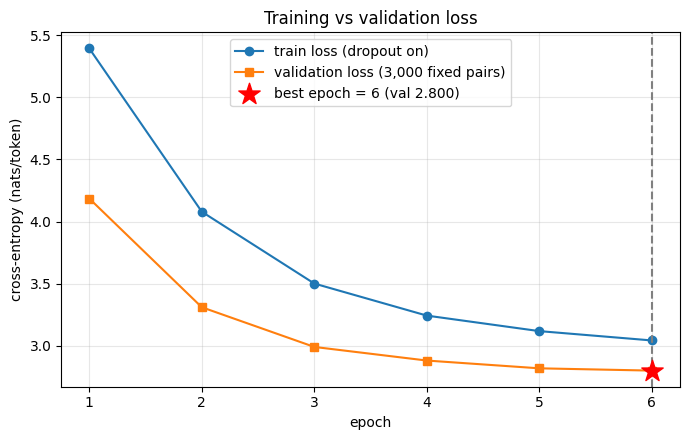

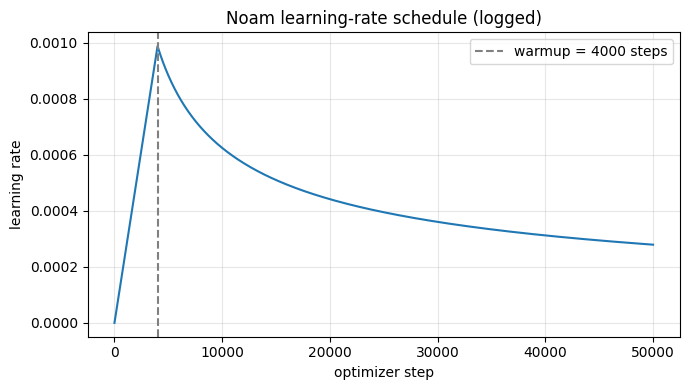

In [9]:
FIG = f"{CFG.out_dir}/figures"; os.makedirs(FIG, exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(HIST["epoch"], HIST["train_loss"], "o-", label="train loss (dropout on)")
ax.plot(HIST["epoch"], HIST["val_loss"], "s-", label=f"validation loss ({len(val_d['src']):,} fixed pairs)")
ax.axvline(ST["best_epoch"], ls="--", c="gray")
ax.scatter([ST["best_epoch"]], [ST["best"]], marker="*", s=260, c="red", zorder=5, label=f"best epoch = {ST['best_epoch']} (val {ST['best']:.3f})")
ax.set(xlabel="epoch", ylabel="cross-entropy (nats/token)", title="Training vs validation loss"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(f"{FIG}/loss_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(HIST["lr_steps"], HIST["lr_vals"]); ax.axvline(INFO["warmup"], ls="--", c="gray", label=f"warmup = {INFO['warmup']} steps")
ax.set(xlabel="optimizer step", ylabel="learning rate", title="Noam learning-rate schedule (logged)"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(f"{FIG}/lr_schedule.png", dpi=150); plt.show()

## 9. Test-set generation, ROUGE and Lead-3 baseline
The **best** checkpoint (restored in section 7) is used on the **full test set** (11,490 pairs; this is the first place test *texts* are read, and they are never used for tuning).
Generation: greedy, autoregressive from `[CLS]`, no teacher forcing, encoder run once per batch, max 128 tokens, per-sequence stop at `[SEP]`.
Scoring: `rouge_score` with `use_stemmer=True`, mean per-example **F1 × 100**, four separate columns: ROUGE-1, ROUGE-2, **ROUGE-L** (whole summary as one sequence) and **ROUGE-Lsum** (sentence-level, `"\n"`-separated).
For ROUGE-Lsum the generated text is split into sentences with `nltk.sent_tokenize` (after re-capitalising sentence starts, because the model output is lower-cased and Punkt relies on capitalisation); the reference already contains `"\n"`.
Lead-3 = first three `sent_tokenize` sentences of the article joined by `"\n"`, scored with the identical scorer.

[TEST] using 11,490 of 11,490 pairs (seed 42) -> cache /content/drive/MyDrive/q3_run/cache/test_11490_42_400_128_0.pkl
[TEST] 11,490 pairs used ONLY for final scoring (no tuning, no checkpoint selection).
  decoded 1,280/11,490
  decoded 2,560/11,490
  decoded 3,840/11,490
  decoded 5,120/11,490
  decoded 6,400/11,490
  decoded 7,680/11,490
  decoded 8,960/11,490
  decoded 10,240/11,490
  decoded 11,490/11,490

Test set: 11,490 pairs | F1 x 100 | rouge_score use_stemmer=True | decoding: greedy, max 128 tokens
System                              ROUGE-1  ROUGE-2  ROUGE-L  ROUGE-Lsum
-------------------------------------------------------------------------
Lead-3 (assignment reference)         40.06    17.48    25.02       36.36
Lead-3 (measured here)                40.05    17.48    25.02       36.35
Transformer from scratch (ours)       34.28    13.94    24.50       31.82
Gap: ours - Lead-3 (measured)         -5.78    -3.54    -0.52       -4.52


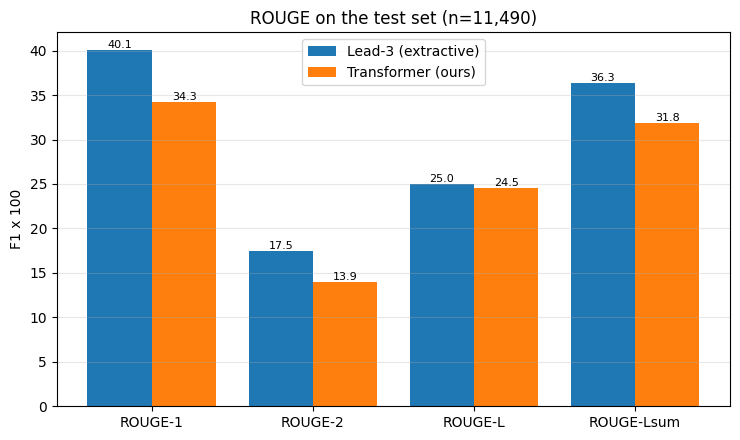

decoding took 4.8 min; results.json and predictions.json saved


In [10]:
test_d, test_sub = load_split("test", CFG.test_subset, SEED, targets=False)
test_articles, test_refs, test_ids = list(test_sub["article"]), list(test_sub["highlights"]), test_d["ids"]
print(f"[TEST] {len(test_refs):,} pairs used ONLY for final scoring (no tuning, no checkpoint selection).")

@torch.no_grad()
def generate_all(model, src_list, bs, cache_path):
    """Batched greedy decoding in length-sorted order; returns token-id lists (before [SEP]) in the original order.
    Progress is cached on disk every 20 batches (keyed by the best checkpoint), so a disconnect never costs the whole decoding run."""
    order, outs, start = np.argsort([len(s) for s in src_list], kind="stable"), [None] * len(src_list), 0
    key = (ST["best_epoch"], round(ST["best"], 6), len(src_list), bs)
    if os.path.exists(cache_path):
        c = torch.load(cache_path, weights_only=False)
        if c["key"] == key:
            outs, start = c["outs"], c["next"]; print(f"  reusing cached decoding up to {start:,}/{len(order):,}")
    model.eval()
    for b, i in enumerate(range(start, len(order), bs)):
        ids = order[i:i + bs]
        src = pad_seqs([src_list[j] for j in ids]).to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            gen, _ = greedy_decode(model, src, BOS, EOS, PAD, CFG.max_tgt)
        for j, row in zip(ids, gen.tolist()):
            row = row[:row.index(EOS)] if EOS in row else row
            outs[j] = [t for t in row if t != PAD]
        if b % 20 == 19 or i + bs >= len(order):
            atomic_save(dict(key=key, outs=outs, next=min(i + bs, len(order))), cache_path)
            print(f"  decoded {min(i + bs, len(order)):,}/{len(order):,}")
    return outs

def split_sents(text):
    """Sentence-split generated text for ROUGE-Lsum: re-capitalise sentence starts, then nltk.sent_tokenize, join with newlines."""
    text = re.sub(r"(^|[.!?]\s+)([a-z])", lambda m: m.group(1) + m.group(2).upper(), text.strip())
    return "\n".join(nltk.sent_tokenize(text))

def score_all(preds, refs):
    """Mean F1 x 100 for rouge1 / rouge2 / rougeL / rougeLsum over all pairs."""
    rows = [SCORER.score(r, p) for r, p in zip(refs, preds)]
    return {k: 100 * float(np.mean([s[k].fmeasure for s in rows])) for k in ROUGE_KEYS}

t0 = time.time()
gen_ids = generate_all(model, test_d["src"], CFG.eval_batch_size, f"{CFG.ckpt_dir}/gen_cache.pkl")
gen_minutes = (time.time() - t0) / 60
gen_texts = tok.batch_decode(gen_ids, skip_special_tokens=True, clean_up_tokenization_spaces=True)   # ids -> text BEFORE scoring
gen_sent = [split_sents(t) for t in gen_texts]
MODEL_ROUGE = score_all(gen_sent, test_refs)
lead3 = ["\n".join(nltk.sent_tokenize(a)[:3]) for a in test_articles]
LEAD3_ROUGE = score_all(lead3, test_refs)
REF_LEAD3 = dict(rouge1=40.06, rouge2=17.48, rougeL=25.02, rougeLsum=36.36)       # values given in the assignment

hdr = f"{'System':34s}{'ROUGE-1':>9s}{'ROUGE-2':>9s}{'ROUGE-L':>9s}{'ROUGE-Lsum':>12s}"
print(f"\nTest set: {len(test_refs):,} pairs | F1 x 100 | rouge_score use_stemmer=True | decoding: greedy, max {CFG.max_tgt} tokens\n" + hdr + "\n" + "-" * len(hdr))
for name, r in (("Lead-3 (assignment reference)", REF_LEAD3), ("Lead-3 (measured here)", LEAD3_ROUGE), ("Transformer from scratch (ours)", MODEL_ROUGE)):
    print(f"{name:34s}" + "".join(f"{r[k]:{w}.2f}" for k, w in zip(ROUGE_KEYS, (9, 9, 9, 12))))
print(f"{'Gap: ours - Lead-3 (measured)':34s}" + "".join(f"{MODEL_ROUGE[k] - LEAD3_ROUGE[k]:{w}.2f}" for k, w in zip(ROUGE_KEYS, (9, 9, 9, 12))))

labels = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum"]; x = np.arange(4)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
b1 = ax.bar(x - .2, [LEAD3_ROUGE[k] for k in ROUGE_KEYS], .4, label="Lead-3 (extractive)")
b2 = ax.bar(x + .2, [MODEL_ROUGE[k] for k in ROUGE_KEYS], .4, label="Transformer (ours)")
ax.bar_label(b1, fmt="%.1f", fontsize=8); ax.bar_label(b2, fmt="%.1f", fontsize=8)
ax.set_xticks(x, labels); ax.set(ylabel="F1 x 100", title=f"ROUGE on the test set (n={len(test_refs):,})"); ax.legend(); ax.grid(axis="y", alpha=.3)
fig.tight_layout(); fig.savefig(f"{FIG}/rouge_vs_lead3.png", dpi=150); plt.show()

RESULTS["rouge"] = dict(model=MODEL_ROUGE, lead3=LEAD3_ROUGE, lead3_assignment_reference=REF_LEAD3)
RESULTS["test"] = dict(n=len(test_refs), decoding="greedy, autoregressive, no teacher forcing, encoder output reused, max 128 tokens (incl. start)",
                       scorer="rouge_score, use_stemmer=True, F1 x 100", decode_minutes=gen_minutes,
                       avg_gen_tokens=float(np.mean([len(g) + 1 for g in gen_ids])), checkpoint=f"best (epoch {ST['best_epoch']})")
json.dump([dict(id=i, reference=r, generated=g) for i, r, g in zip(test_ids, test_refs, gen_texts)], open(f"{CFG.out_dir}/predictions.json", "w"))
save_results()
print(f"decoding took {gen_minutes:.1f} min; results.json and predictions.json saved")

## 10. Qualitative examples and failure analysis
Every generated summary is flagged programmatically: **repetition** (any word trigram occurring ≥ 2 times, plus the repeated-trigram ratio),
**numbers absent from the article**, and **words absent from the article** (alphabetic, ≥ 4 chars, Porter-stem match; since the model output is lower-cased this is our proxy for invented names/entities).
"typical" examples are drawn at random (fixed seed) among summaries with no flags (if fewer than four exist, the least-flagged ones are used); the two failure cases are picked by these flags (highest repetition, most unsupported content). The short analyses are generated from the flags.

In [11]:
stem = lru_cache(maxsize=None)(nltk.stem.PorterStemmer().stem)
def words(t): return re.findall(r"[a-z0-9]+(?:[.,][0-9]+)*", t.lower())
def trigrams(w): return [tuple(w[i:i + 3]) for i in range(len(w) - 2)]

def flags(article, gen):
    """Heuristic quality flags for one (article, generated summary) pair."""
    gw, aw = words(gen), words(article); aset = set(aw)
    tri = Counter(trigrams(gw))
    rep = {" ".join(k): v for k, v in tri.items() if v > 1}
    bad_nums = sorted({w.replace(",", "") for w in gw if w[0].isdigit()} - {w.replace(",", "") for w in aset if w[0].isdigit()})
    cand = {w for w in gw if w.isalpha() and len(w) >= 4 and w not in aset}
    a_stems = {stem(w) for w in aset} if cand else set()
    novel = sorted(w for w in cand if stem(w) not in a_stems)
    atri = set(trigrams(aw)); gt = trigrams(gw)
    return dict(rep_ratio=1 - len(tri) / max(1, sum(tri.values())), repeated=rep, bad_numbers=bad_nums, novel_words=novel,
                copy_rate=sum(t in atri for t in gt) / max(1, len(gt)), n_words=len(gw))

FL = [flags(a, g) for a, g in zip(test_articles, gen_texts)]
DIAG = dict(pct_with_repeated_trigram=100 * np.mean([bool(f["repeated"]) for f in FL]),
            pct_with_unsupported_number=100 * np.mean([bool(f["bad_numbers"]) for f in FL]),
            pct_with_unsupported_word=100 * np.mean([bool(f["novel_words"]) for f in FL]),
            mean_trigram_copy_rate_pct=100 * np.mean([f["copy_rate"] for f in FL]),
            mean_gen_words=float(np.mean([f["n_words"] for f in FL])), mean_ref_words=float(np.mean([len(words(r)) for r in test_refs])))
RESULTS["diagnostics"] = {k: float(v) for k, v in DIAG.items()}
print({k: round(float(v), 1) for k, v in DIAG.items()})

rng = random.Random(SEED); N = len(gen_texts); all_idx = list(range(N))
pool = [i for i in all_idx if not FL[i]["repeated"] and not FL[i]["bad_numbers"] and len(FL[i]["novel_words"]) <= 1 and FL[i]["n_words"] >= 12]
n_pool = min(4, len(pool)); clean = rng.sample(pool, n_pool)                                          # unflagged summaries, random (fixed seed)
clean += sorted((i for i in all_idx if i not in clean), key=lambda i: FL[i]["rep_ratio"] + len(FL[i]["bad_numbers"]) + len(FL[i]["novel_words"]))[:max(0, 4 - len(clean))]
fail_rep = max((i for i in all_idx if i not in clean), key=lambda i: FL[i]["rep_ratio"])
fail_fact = max((i for i in all_idx if i not in clean + [fail_rep]), key=lambda i: 3 * len(FL[i]["bad_numbers"]) + len(FL[i]["novel_words"]))
picks = [("typical" if k < n_pool else "least-flagged (no unflagged example left)", i) for k, i in enumerate(clean)] + [("FAILURE: repetition", fail_rep), ("FAILURE: unsupported facts", fail_fact)]

def analysis(kind, f):
    if not kind.startswith("FAILURE"):
        return (f"{f['copy_rate'] * 100:.0f}% of the summary's word trigrams occur verbatim in the article; repeated-trigram ratio {f['rep_ratio'] * 100:.0f}%; "
                f"unsupported numbers: {len(f['bad_numbers'])}, unsupported words: {len(f['novel_words'])}.")
    if "repetition" in kind:
        top = max(f["repeated"].items(), key=lambda kv: kv[1]) if f["repeated"] else ("none", 0)
        return f"Repeated-trigram ratio {f['rep_ratio'] * 100:.0f}%; most repeated trigram: '{top[0]}' x{top[1]}. Typical greedy-decoding loop without coverage/repetition control."
    return (f"Numbers not in the article: {f['bad_numbers'] or 'none'}; words not in the article: {f['novel_words'][:8] or 'none'}. "
            "The model substitutes plausible-looking but unsupported content (no pointer/copy mechanism).")

QUAL = []
for kind, i in picks:
    s = SCORER.score(test_refs[i], gen_sent[i]); ana = analysis(kind, FL[i])
    QUAL.append(dict(kind=kind, test_index=i, id=test_ids[i], article_snippet=test_articles[i][:600], reference=test_refs[i], generated=gen_texts[i],
                     rouge1=100 * s["rouge1"].fmeasure, rougeLsum=100 * s["rougeLsum"].fmeasure, analysis=ana))
    print(f"\n=== [{kind}] test #{i} | ROUGE-1 {QUAL[-1]['rouge1']:.1f} | ROUGE-Lsum {QUAL[-1]['rougeLsum']:.1f}")
    print("ARTICLE :", test_articles[i][:600].replace("\n", " "), "...")
    print("REFERENCE:", test_refs[i].replace("\n", " | "))
    print("GENERATED:", gen_texts[i])
    print("ANALYSIS :", ana)
RESULTS["qualitative"] = QUAL; save_results()

{'pct_with_repeated_trigram': 68.1, 'pct_with_unsupported_number': 9.3, 'pct_with_unsupported_word': 20.8, 'mean_trigram_copy_rate_pct': 69.2, 'mean_gen_words': 48.4, 'mean_ref_words': 52.8}

=== [typical] test #9700 | ROUGE-1 30.1 | ROUGE-Lsum 30.1
ARTICLE : We have all been there. Wanting to get online but just out of wifi coverage. However in central China, Mother Nature recently appeared to lend a helping hand by giving locals what could be the world's largest 'Wi-Fi cloud'. A cloud formation resembling the Wi-Fi symbol appeared recently in the sky of Xiangtan city in Hunan Province, the People's Daily Online reports. God's router? A cloud formation resembling the Wi-Fi symbol appeared in central China last week . The global Wi-Fi symbol has one dot and three curved lines radiating from it . Shi Chao, a student at the Hunan University of Scienc ...
REFERENCE: Cloud appeared in central China's Hunan province last Friday . | A university student snapped the moment on his way to the l

## 11. Encoder-decoder (cross) attention heatmaps
For one test article, summary generation is re-run greedily (no teacher forcing) while recording the cross-attention of the **last decoder layer** at every generation step.
Main figure: **averaged over all heads**; second figure: **each head separately**. Rows = generated summary tokens, columns = an 80-token window of the source where most of the attention mass falls (window start chosen by maximal mass), tokens as axis labels.

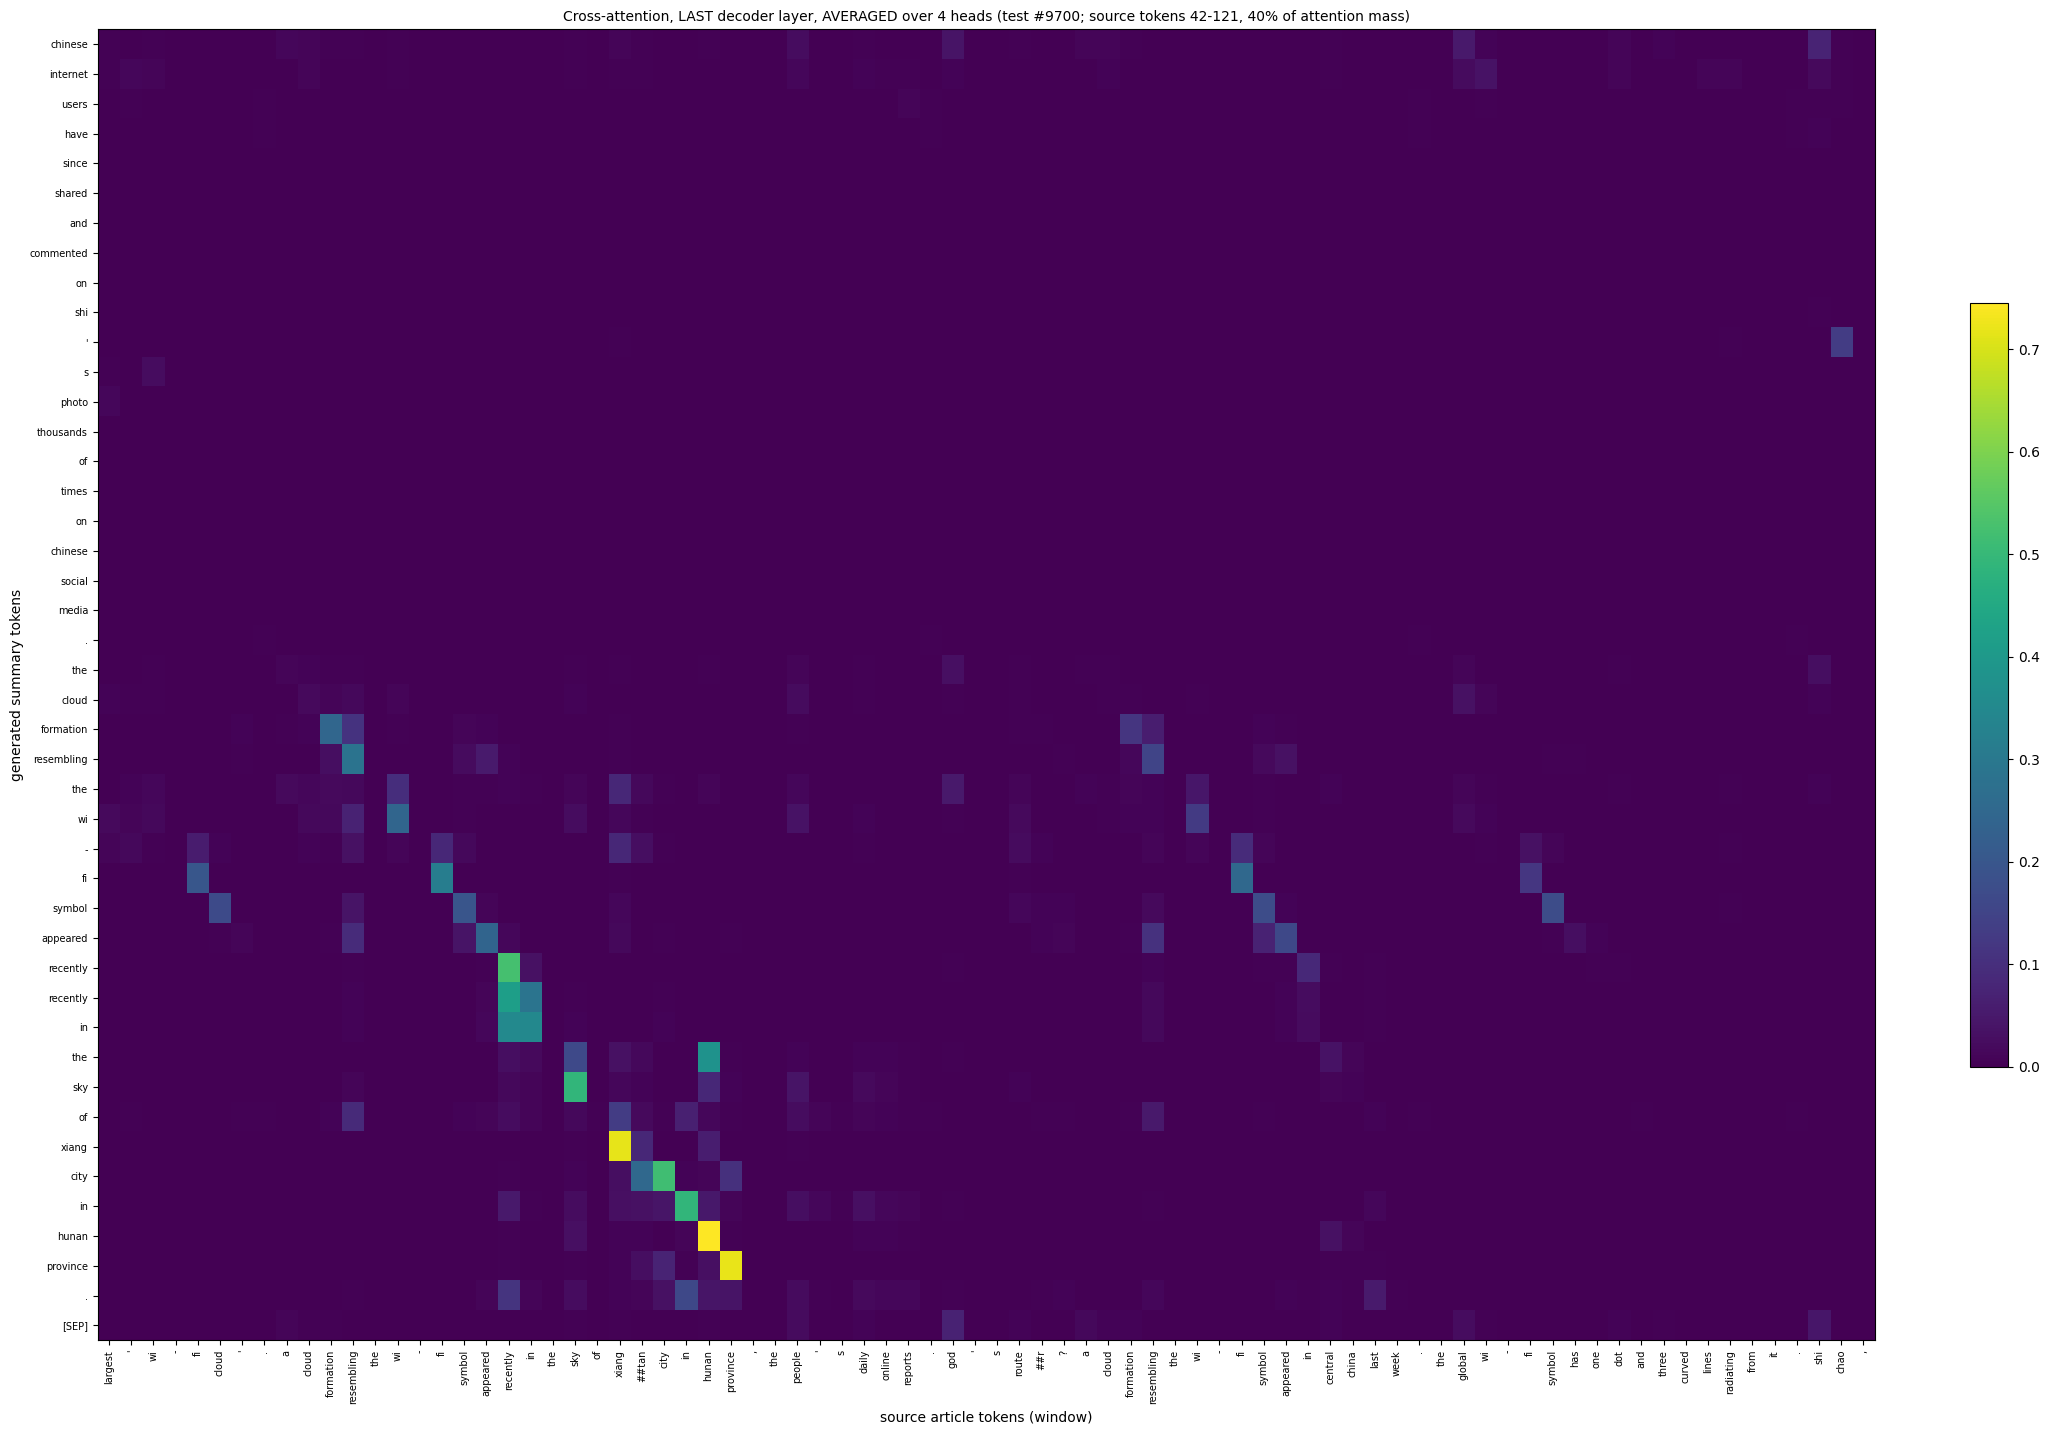

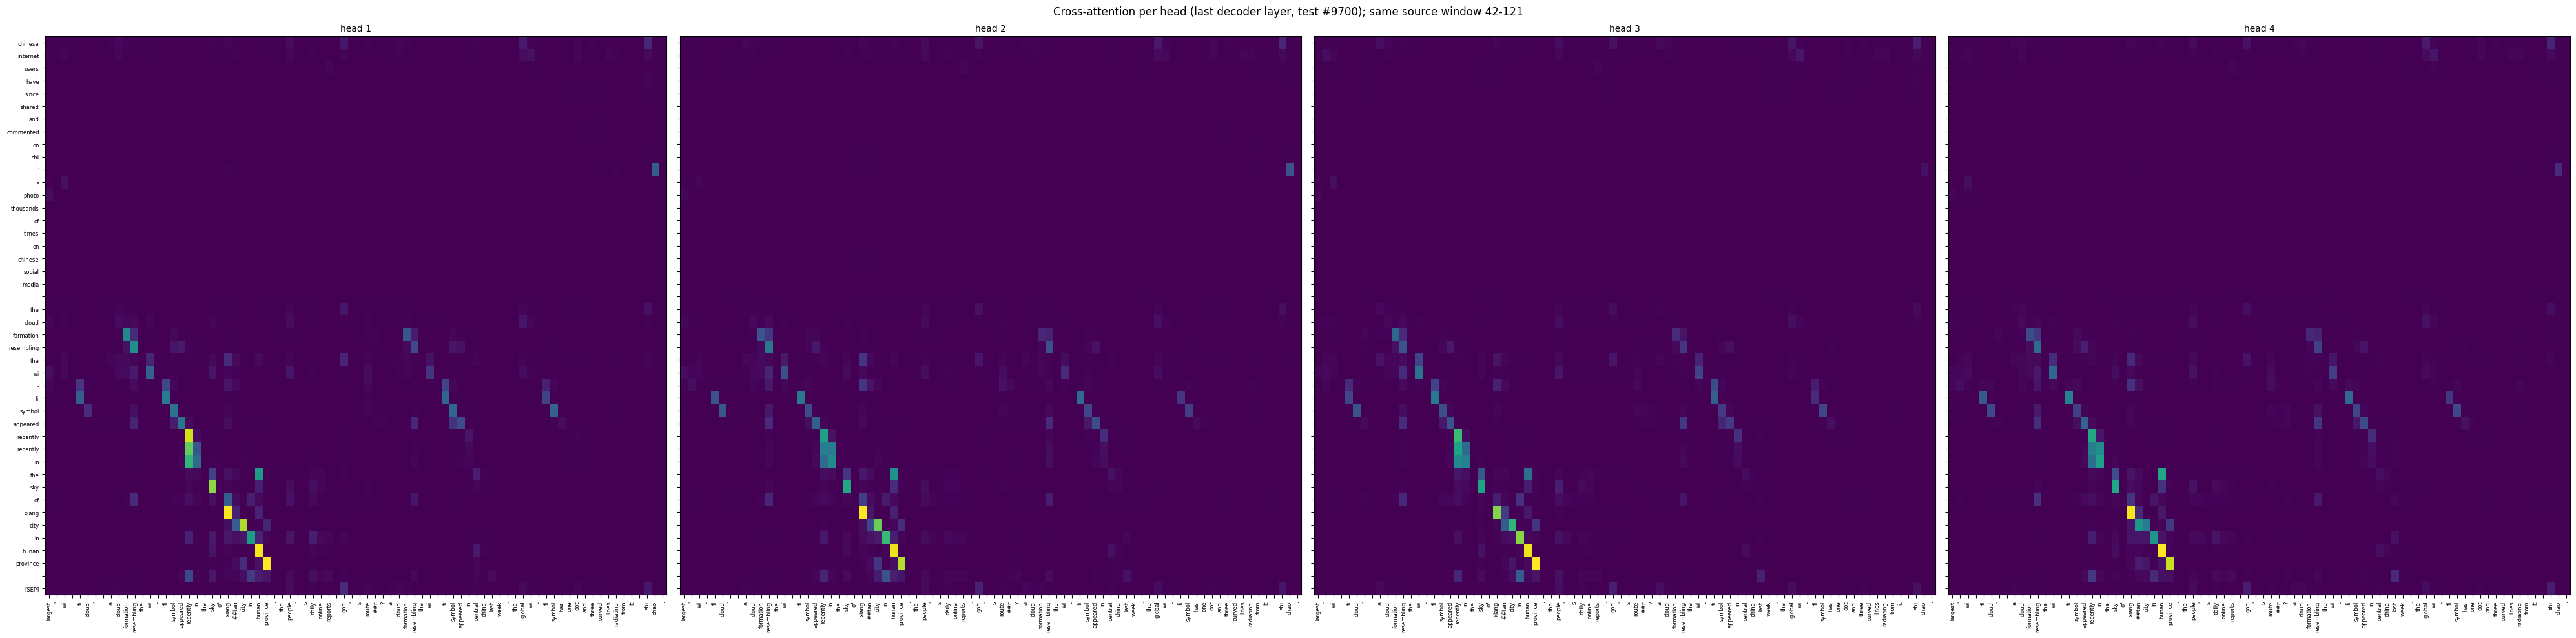

Averaged over heads, 40% of the attention mass of this example falls inside the shown 80-token window (source tokens 42-121). For 70% of the generated tokens the most-attended source token is the identical word piece (copy-like alignment). The mean attention entropy is 3.19 nats; a perfectly uniform distribution over the 400 source tokens would give 5.99. Attention is clearly concentrated (53% of the uniform entropy), i.e. the decoder focuses on specific source words while generating. 48% of the attention peaks lie in the first 100 source tokens (news puts key facts first). Per-head entropy ranges from 3.01 (sharpest head) to 3.28 nats (most diffuse head), i.e. all heads behave similarly.


In [12]:
cand = [i for i in clean + all_idx if 18 <= len(gen_ids[i]) <= 45 and len(test_d["src"][i]) >= 120]
ai = cand[0] if cand else clean[0]
src_t = torch.from_numpy(test_d["src"][ai].astype(np.int64))[None].to(DEVICE)
with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
    g, att = greedy_decode(model, src_t, BOS, EOS, PAD, CFG.max_tgt, capture=True)            # att: (1,H,steps,S)
row = g[0].tolist(); Tg = (row.index(EOS) + 1) if EOS in row else len(row)
att = att[0, :, :Tg, :].numpy()                                                                # (H,Tg,S)
gen_tok = tok.convert_ids_to_tokens(row[:Tg]); src_tok = tok.convert_ids_to_tokens(test_d["src"][ai].tolist())
S, W = att.shape[-1], min(80, att.shape[-1]); avg = att.mean(0)                                # head average (Tg,S)
cs = np.concatenate([[0], np.cumsum(avg.sum(0))]); w0 = int(np.argmax(cs[W:] - cs[:-W])); w1 = w0 + W
mass = float(avg[:, w0:w1].sum() / avg.sum())

def heat(ax, M, title, xl=True, yl=True, fs=7):
    im = ax.imshow(M, aspect="auto", cmap="viridis", vmin=0)
    ax.set_xticks(range(W)); ax.set_xticklabels(src_tok[w0:w1] if xl else [], rotation=90, fontsize=fs)
    ax.set_yticks(range(Tg)); ax.set_yticklabels(gen_tok if yl else [], fontsize=fs); ax.set_title(title, fontsize=10); return im

fig, ax = plt.subplots(figsize=(0.22 * W + 3, 0.26 * Tg + 3))
im = heat(ax, avg[:, w0:w1], f"Cross-attention, LAST decoder layer, AVERAGED over {att.shape[0]} heads (test #{ai}; source tokens {w0}-{w1 - 1}, {mass * 100:.0f}% of attention mass)")
ax.set_xlabel("source article tokens (window)"); ax.set_ylabel("generated summary tokens"); fig.colorbar(im, ax=ax, fraction=.02)
fig.tight_layout(); fig.savefig(f"{FIG}/attention_avg.png", dpi=150); plt.show()

nh = att.shape[0]; cols = 4 if nh >= 4 else nh; rows_ = math.ceil(nh / cols)
fig, axs = plt.subplots(rows_, cols, figsize=(cols * (0.1 * W + 2), rows_ * (0.16 * Tg + 3)), squeeze=False)
for h in range(rows_ * cols):
    a = axs[h // cols][h % cols]
    if h < nh: heat(a, att[h][:, w0:w1], f"head {h + 1}", xl=h // cols == rows_ - 1, yl=h % cols == 0, fs=6)
    else: a.axis("off")
fig.suptitle(f"Cross-attention per head (last decoder layer, test #{ai}); same source window {w0}-{w1 - 1}", fontsize=12)
fig.tight_layout(); fig.savefig(f"{FIG}/attention_heads.png", dpi=130); plt.show()

peak = avg.argmax(1); copy_frac = float(np.mean([src_tok[p] == t for p, t in zip(peak, gen_tok)]))
lead_frac = float(np.mean(peak < 100)); ent = float(-(avg * np.log(avg + 1e-12)).sum(1).mean())
head_ent = [float(-(att[h] * np.log(att[h] + 1e-12)).sum(1).mean()) for h in range(att.shape[0])]
ln_u = math.log(S)
INTERP = (f"Averaged over heads, {mass * 100:.0f}% of the attention mass of this example falls inside the shown {W}-token window (source tokens {w0}-{w1 - 1}). "
          f"For {copy_frac * 100:.0f}% of the generated tokens the most-attended source token is the identical word piece (copy-like alignment). "
          f"The mean attention entropy is {ent:.2f} nats; a perfectly uniform distribution over the {S} source tokens would give {ln_u:.2f}. "
          + ("Attention is therefore close to uniform: the model has NOT learned a sharp article-to-summary alignment, so this heatmap shows little focus. "
             if ent > 0.9 * ln_u else
             f"Attention is clearly concentrated ({ent / ln_u * 100:.0f}% of the uniform entropy), i.e. the decoder focuses on specific source words while generating. ")
          + f"{lead_frac * 100:.0f}% of the attention peaks lie in the first 100 source tokens (news puts key facts first). "
          f"Per-head entropy ranges from {min(head_ent):.2f} (sharpest head) to {max(head_ent):.2f} nats (most diffuse head)"
          + (", i.e. the heads specialise differently." if max(head_ent) - min(head_ent) > 0.3 else ", i.e. all heads behave similarly."))
print(INTERP)
RESULTS["attention"] = dict(test_index=int(ai), generated=gen_tok, window=[w0, w1], mass_in_window=mass, copy_fraction=copy_frac,
                            lead100_fraction=lead_frac, entropy=ent, n_heads=int(nh), interpretation=INTERP)
save_results()

## 12. Auto-generated `REPORT.docx`
Every run-dependent number and table is read from `results.json`; figures are the PNGs saved above. Static prose only contains method descriptions and general explanations.

In [ ]:
from docx import Document
from docx.shared import Inches

R = json.load(open(RESULTS_PATH))
D, M, T, RG, TS, DG, AT = R["data"], R["model"], R["training"], R["rouge"], R["test"], R["diagnostics"], R["attention"]
doc = Document()
def H(t, lvl=1): doc.add_heading(t, level=lvl)
def P(t): doc.add_paragraph(t)
def table(header, rows):
    t = doc.add_table(rows=1, cols=len(header)); t.style = "Table Grid"
    for c, h in zip(t.rows[0].cells, header): c.text = str(h)
    for r in rows:
        for c, v in zip(t.add_row().cells, r): c.text = str(v)
def fig(name, caption, w=6.0):
    p = f"{FIG}/{name}"
    if os.path.exists(p): doc.add_picture(p, width=Inches(w)); P(caption)
def r4(d): return [f"{d[k]:.2f}" for k in ROUGE_KEYS]

doc.add_heading("Abstractive Text Summarization with a From-Scratch Transformer (CNN/DailyMail 3.0.0)", 0)
H("1. Introduction")
P("We implement a full Transformer encoder-decoder (Vaswani et al., 2017) from scratch with only nn.Linear, nn.Embedding, nn.LayerNorm, nn.Dropout and tensor operations, "
  "train it on CNN/DailyMail 3.0.0 for abstractive summarization, and evaluate it with ROUGE on the full test set against the extractive Lead-3 baseline. No pretrained model weights are used; only the pretrained bert-base-uncased tokenizer.")
H("2. Dataset and preprocessing")
sz = D["split_sizes"]
P(f"Dataset: {D['dataset']} (train {sz['train']:,} / validation {sz['validation']:,} / test {sz['test']:,}). Tokenizer: {D['tokenizer']}; one shared vocabulary of {D['vocab_size']:,} tokens for articles and summaries; "
  f"[CLS] = start token, [SEP] = end token, [PAD] = padding. Articles are truncated to {D['max_src']} tokens; summaries to {D['max_tgt']} tokens including the start and end tokens. "
  f"Decoder input = summary shifted right (starts with [CLS]); target = summary shifted left (ends with [SEP]). Raw references keep the newline between highlight sentences for ROUGE-Lsum.")
P(f"Training-set size actually used: {D['train_used']:,} pairs randomly sampled (seed {D['seed']}) from the training split only. Validation: a fixed subset of {D['val_used']:,} pairs for early stopping. Test: {TS['n']:,} pairs, used only for final scoring. Batches are length-bucketed and tokenised tensors are cached.")
L = D["length_stats"]
table(["", "Median", "90th pct", "Max", "% over limit"], [[k.capitalize(), f"{v['median']:.0f}", f"{v['p90']:.0f}", v["max"], f"{v['pct_over_limit']:.1f}"] for k, v in L.items()])
P("Token lengths measured on a 2,000-article validation sample (the test split is never used for statistics).")
H("3. Model architecture")
table(["Setting", "Value"], [["d_model", M["d_model"]], ["Encoder / decoder layers", f"{M['n_layers']} / {M['n_layers']}"], ["Attention heads", M["n_heads"]],
                             ["d_ff", M["d_ff"]], ["Dropout", M["dropout"]], ["Embeddings", "tied: encoder = decoder = output projection"],
                             ["Total parameters", f"{M['params']['total']:,}"], ["  tied embedding matrix", f"{M['params']['embedding_tied']:,}"],
                             ["  encoder layers", f"{M['params']['encoder_layers']:,}"], ["  decoder layers", f"{M['params']['decoder_layers']:,}"]])
P("Components: scaled dot-product attention softmax(QK^T/sqrt(d_k)+mask)V with masked scores set to a large negative finite value and a fp32 softmax; multi-head attention; position-wise FFN; sinusoidal positional encodings; "
  "post-LN sub-layers LayerNorm(x + Dropout(Sublayer(x))). Three masks: source padding mask (encoder self-attention and cross-attention) and causal mask combined with target padding mask (decoder self-attention). A final linear layer (tied to the embedding) maps decoder states to vocabulary logits.")
H("4. Training setup and results")
P(f"Loss: cross-entropy with ignore_index=pad (label smoothing {T['label_smoothing']}); optimizer {T['optimizer']}; warm-up {T['warmup_steps_effective']} steps (configured {T['warmup_steps_config']}, capped at 20% of the planned {T['planned_total_steps']} steps so small subsets still decay); "
  f"teacher forcing; mixed precision (AMP: {T['amp']}); gradient clipping {T['grad_clip']}; batch size {T['batch_size']}; device {T['device']}. Validation loss every epoch on {T['val_subset']:,} fixed pairs; early stopping patience {T['patience']}; the best checkpoint is restored before testing.")
P(f"Epochs run: {T['epochs_run']} of {T['max_epochs']} (stop reason: {T['stop_reason']}). Best epoch: {T['best_epoch']} with validation loss {T['best_val_loss']:.4f}. Training time: {T['train_minutes']:.1f} min, {T['steps_done']:,} optimizer steps.")
if "source_ablation" in T:
    A = T["source_ablation"]
    P(f"Source-ablation check (validation subset, teacher forced): loss with the true article {A['loss_true_article']:.4f} vs {A['loss_wrong_article']:.4f} when every summary is paired with another example's article "
      f"(gap {A['gap']:+.4f} nats/token). A model that conditions on its input must be clearly worse with the wrong article; a gap near zero would mean the decoder ignores the source.")
h = T["history"]
table(["Epoch", "Train loss", "Val loss", "Minutes"], [[e, f"{a:.4f}", f"{b:.4f}", f"{m:.1f}"] for e, a, b, m in zip(h["epoch"], h["train_loss"], h["val_loss"], h["epoch_minutes"])])
H("5. Decoding method")
P(f"{TS['decoding']}. Each article batch is encoded once and the encoder output is reused at every step; each sequence stops at [SEP]. Token ids are converted to text (special tokens skipped, spaces cleaned) before scoring. Checkpoint evaluated: {TS['checkpoint']}.")
H("6. Quantitative results")
P(f"ROUGE F1 x 100 on the full test set ({TS['n']:,} pairs), rouge_score with use_stemmer=True. ROUGE-L treats the summary as one sequence; ROUGE-Lsum works sentence by sentence on newline-separated sentences (generated text split with nltk.sent_tokenize); both are reported and labelled.")
table(["System", "ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum"],
      [["Lead-3 (assignment reference)"] + r4(RG["lead3_assignment_reference"]), ["Lead-3 (measured here)"] + r4(RG["lead3"]), ["Transformer from scratch (ours)"] + r4(RG["model"])])
fig("rouge_vs_lead3.png", "Figure 1: ROUGE vs Lead-3 on the test set.", 5.5)
H("7. Loss curves")
fig("loss_curves.png", "Figure 2: training vs validation loss; the star marks the best epoch.", 5.5)
fig("lr_schedule.png", "Figure 3: logged Noam learning-rate schedule.", 5.0)
H("8. Qualitative analysis")
P(f"Over the {TS['n']:,} generated test summaries: {DG['pct_with_repeated_trigram']:.1f}% contain a repeated word trigram, {DG['pct_with_unsupported_number']:.1f}% contain a number absent from the article, "
  f"{DG['pct_with_unsupported_word']:.1f}% contain a word (>=4 letters) absent from the article, and on average {DG['mean_trigram_copy_rate_pct']:.1f}% of summary trigrams are copied verbatim from the article. "
  f"Mean length: {DG['mean_gen_words']:.1f} generated vs {DG['mean_ref_words']:.1f} reference words. Failure cases were selected with these flags.")
for q in R["qualitative"]:
    H(f"{q['kind']} (test #{q['test_index']}, id {q['id']})", 3)
    P("Article (start): " + q["article_snippet"].replace("\n", " ") + " ..."); P("Reference: " + q["reference"].replace("\n", " | "))
    P("Generated: " + q["generated"]); P(f"ROUGE-1 {q['rouge1']:.1f} | ROUGE-Lsum {q['rougeLsum']:.1f}. Analysis: {q['analysis']}")
H("9. Attention visualization")
P(f"Encoder-decoder attention of the last decoder layer, recorded while the model generates (greedy, no teacher forcing) for test example #{AT['test_index']}. Figure 4 averages over all {AT['n_heads']} heads; Figure 5 shows each head. "
  f"Rows are generated tokens, columns a window of source tokens {AT['window'][0]}-{AT['window'][1] - 1}.")
fig("attention_avg.png", "Figure 4: head-averaged cross-attention heatmap.", 6.5); fig("attention_heads.png", "Figure 5: per-head cross-attention.", 6.5)
P(AT["interpretation"])
H("10. Limitations and discussion")
gap = RG["lead3"]["rougeLsum"] - RG["model"]["rougeLsum"]
P(f"The from-scratch model scores {RG['model']['rougeLsum']:.2f} ROUGE-Lsum vs {RG['lead3']['rougeLsum']:.2f} for Lead-3 (gap {gap:+.2f}). " + ("It stays below Lead-3, as expected, for these reasons: " if gap > 0 else "Unusually it reaches Lead-3 level; the usual obstacles are: ") +
  f"(1) limited data and epochs: {D['train_used']:,} of {sz['train']:,} training pairs and {T['epochs_run']} epochs; (2) Lead-3 is extractive and copies exact reference-style sentences, which is a very strong prior on news, whereas an abstractive model must learn to generate fluent text; "
  f"(3) copy behaviour: without a pointer-generator mechanism the model must re-generate names and numbers from a {D['vocab_size']:,}-token word-piece vocabulary and often fails on rare entities; (4) tokenization: lower-cased word pieces split names into fragments and lose casing; "
  f"(5) exposure bias: training uses gold prefixes, decoding feeds back its own mistakes; (6) greedy decoding without repetition control produces loops ({DG['pct_with_repeated_trigram']:.1f}% of summaries); "
  f"(7) articles are truncated to {D['max_src']} tokens ({L['article']['pct_over_limit']:.1f}% of articles are longer) and the validation subset ({D['val_used']:,}) is only a proxy for generalisation.")
H("11. Conclusion")
P(f"A {M['params']['total'] / 1e6:.1f}M-parameter Transformer with tied embeddings, trained from scratch on {D['train_used']:,} pairs, reaches ROUGE-1/2/L/Lsum of "
  f"{RG['model']['rouge1']:.2f}/{RG['model']['rouge2']:.2f}/{RG['model']['rougeL']:.2f}/{RG['model']['rougeLsum']:.2f} on the full test set (Lead-3 measured: "
  f"{RG['lead3']['rouge1']:.2f}/{RG['lead3']['rouge2']:.2f}/{RG['lead3']['rougeL']:.2f}/{RG['lead3']['rougeLsum']:.2f}). All components, masks and the decoder were implemented and verified by sanity checks.")
REPORT_PATH = f"{CFG.out_dir}/REPORT.docx"; doc.save(REPORT_PATH); print("saved", REPORT_PATH)

## 13. README.md and `submission.zip`
The zip contains the notebook, a `.py` export of the executed cells, README, REPORT.docx, figures, `results.json` and `predictions.json`. It excludes the dataset, the Hugging Face cache, the token caches and checkpoints.

In [14]:
import glob
README = f"""# Q3 - Abstractive summarization with a from-scratch Transformer (CNN/DailyMail 3.0.0)

## Requirements
Python 3.10+, GPU recommended (Colab/Kaggle T4). `pip install torch datasets transformers rouge_score nltk python-docx matplotlib`
(`transformers` is used for the pretrained `bert-base-uncased` *tokenizer only*; no pretrained weights are loaded).

## Run
1. Open `summarizer.ipynb` on Colab/Kaggle with a GPU runtime and use Run All (about 2-2.5 h on a T4: training budget {CFG.time_budget_min:.0f} min).
2. CPU smoke test: set `PRESET = "smoke"` (or env `SUMMARIZER_PRESET=smoke`).
3. Config (model size, TRAIN_SUBSET=`train_subset`, MAX_EPOCHS=`max_epochs`, TIME_BUDGET_MIN=`time_budget_min`, RESUME=`resume`, CKPT_DIR=`ckpt_dir`) lives in the config dataclass of section 2 and `USER_OVERRIDES`.

## Resume after a disconnect
On Colab the notebook mounts Drive and keeps checkpoints, token caches, outputs and the decoding cache in `/content/drive/MyDrive/q3_run`. After a disconnect: reconnect a GPU runtime, Run All, authorise Drive; training continues from the newest checkpoint (written every `ckpt_every` steps, even mid-epoch) and finished decoding batches are reused. Resume needs the same model/data config (checked automatically).

## Files
- `summarizer.ipynb` - full pipeline (data, model, sanity checks, training, evaluation, qualitative, attention, report, zip)
- `summarizer_export.py` - code of the executed cells (if exported)
- `REPORT.docx` - report generated from `results.json`
- `results.json`, `predictions.json` - all numbers and generated test summaries
- `figures/` - loss curves, LR schedule, ROUGE bar chart, attention heatmaps

## Not included
Dataset, Hugging Face cache, tokenised caches and model checkpoints.
"""
open("README.md", "w").write(README)
try:                                              # export source of the executed cells (works in Jupyter/Colab)
    cells_src = [c for c in get_ipython().user_ns["In"] if c and not c.lstrip().startswith(("%", "!"))]
    open("summarizer_export.py", "w").write("\n\n# %%\n".join(cells_src))
except Exception as e:
    print("source export skipped:", type(e).__name__)

ZIP = "submission.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for nbk in glob.glob("*.ipynb"): z.write(nbk)
    for f in ("README.md", "summarizer_export.py", REPORT_PATH, RESULTS_PATH, f"{CFG.out_dir}/predictions.json"):
        if os.path.exists(f): z.write(f, os.path.basename(f))
    for f in glob.glob(f"{FIG}/*.png"): z.write(f, "figures/" + os.path.basename(f))
    print("zip contents:", z.namelist())
if DRIVE_DIR:
    import shutil; shutil.copy(ZIP, f"{DRIVE_DIR}/{ZIP}"); print("zip also copied to Drive:", f"{DRIVE_DIR}/{ZIP}")
if not glob.glob("*.ipynb"):
    print("NOTE: notebook file not found in the working dir - File > Download .ipynb and add it to the zip before submitting.")
try:
    from google.colab import files; files.download(ZIP)
except ImportError:
    print(f"Download link: {os.path.abspath(ZIP)}")

zip contents: ['README.md', 'summarizer_export.py', 'REPORT.docx', 'results.json', 'predictions.json', 'figures/loss_curves.png', 'figures/lr_schedule.png', 'figures/rouge_vs_lead3.png', 'figures/attention_avg.png', 'figures/attention_heads.png']
zip also copied to Drive: /content/drive/MyDrive/q3_run/submission.zip
NOTE: notebook file not found in the working dir - File > Download .ipynb and add it to the zip before submitting.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>